# EM алгоритм. Модель гауссовской смеси.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp, gammaln, digamma, expit
from scipy.optimize import minimize
from scipy.stats import norm
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from IPython.display import display, Markdown

RUN_VAE = False  # В студенческой версии приложение по умолчанию отключено.
SEED = 2026
completed = set()
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True,
                     'grid.alpha': .2, 'font.size': 10})

def check(name, test):
    completed.discard(name)
    try:
        test()
    except NotImplementedError:
        print(f'{name}: заполните реализацию и повторите эту проверку.')
    else:
        completed.add(name)
        print(f'{name}: проверки пройдены.')

def ready(*names):
    missing = set(names) - completed
    if missing:
        print('Сначала завершите: ' + ', '.join(sorted(missing)))
    return not missing

def table(headers, rows):
    fmt = lambda v: f'{v:.4f}' if isinstance(v, (float, np.floating)) else str(v)
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(fmt, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def plot_histogram(ax, values, edges, fill=False, **kwargs):
    """Piecewise-constant density; compatible with Matplotlib 3.3+."""
    heights = np.r_[values, values[-1]]
    if fill:
        return ax.fill_between(edges, heights, step='post', **kwargs)
    return ax.step(edges, heights, where='post', **kwargs)


## 1. Скрытая компонента и наблюдаемое правдоподобие

Пусть $x_i\in\mathbb R^d$, $z_i\in\{1,\ldots,K\}$ и
$$p(z_i=k)=\pi_k,\qquad p(x_i\mid z_i=k)=\mathcal N(x_i;\mu_k,\Sigma_k),
\qquad \pi_k>0,\quad \sum_k\pi_k=1.$$
Маргинальная плотность и логарифм правдоподобия равны
$$p_\theta(x_i)=\sum_k\pi_k\mathcal N(x_i;\mu_k,\Sigma_k),\qquad
\ell(\theta)=\sum_i\log\sum_k\pi_k\mathcal N(x_i;\mu_k,\Sigma_k).$$
Логарифм суммы мешает раздельно оценить компоненты. Если бы $z_i$ были известны,
каждую гауссиану можно было бы обучить на своей группе. EM заменяет неизвестные
индикаторы принадлежности мягкими весами, а не единственной догадкой о метке.

Вопрос: что означает $\pi_k$? Почему $K$ компонент не обязательно дают
$K$ мод плотности? Изменится ли $p_\theta(x)$ при перестановке номеров компонент?


In [ ]:
def make_toy(seed=SEED, n=750):
    rng = np.random.default_rng(seed)
    weights = np.array([.35, .4, .25])
    means = np.array([[-2., -1.], [1.2, 1.5], [3.2, -1.5]])
    covs = np.array([[[.5, 0], [0, .18]], [[.7, 0], [0, .35]],
                     [[.24, 0], [0, .65]]])
    labels = rng.choice(3, n, p=weights)
    X = np.vstack([rng.multivariate_normal(means[k], covs[k]) for k in labels])
    return X, labels

X_toy, toy_truth = make_toy()
plt.scatter(*X_toy.T, s=9, alpha=.5, color='steelblue')
plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title('Наблюдения: метки скрыты')
plt.show()


## 2. EM как покоординатный подъём ELBO

Для любых распределений $q_i(k)$ на компонентах введём
$$\mathcal F(q,\theta)=\sum_{i,k}q_i(k)
   [\log\pi_k+\log p_\theta(x_i\mid k)-\log q_i(k)].$$
Из формулы Байеса следует точное тождество
$$\ell(\theta)=\mathcal F(q,\theta)+
\sum_i D_{\rm KL}(q_i\|p_\theta(z_i\mid x_i)).$$
Здесь $0\log0=0$; KL неотрицательна. Поэтому $\mathcal F$ — нижняя граница.

E-шаг: при фиксированном $\theta^{(t)}$ выбрать
$q_i(k)=r_{ik}=p_{\theta^{(t)}}(z_i=k\mid x_i)$; зазор становится нулевым.
M-шаг: при фиксированных $r$ максимизировать
$Q(\theta)=\sum_{i,k}r_{ik}\log p_\theta(x_i,z_i=k)$.
Энтропия $q$ от новых параметров не зависит.

В результате точных шагов $\ell(\theta^{(t+1)})\geq\ell(\theta^{(t)})$.
Это не гарантия глобального максимума. Совпадение границы с правдоподобием
происходит после E-шага для текущих параметров, а не для любых $q,\theta$.

В VAE вместо точного постериора используется ограниченное семейство
$q_\phi(z\mid x)$ и градиентная оптимизация. Для конечной смеси сумма по $k$
вычисляется точно; сэмплировать дискретную метку для E-шага не требуется.

На доске: выведите тождество, раскрыв KL. Докажите цепочку
$\ell(\theta^{(t+1)})\geq\mathcal F(q^{(t)},\theta^{(t+1)})
\geq\mathcal F(q^{(t)},\theta^{(t)})=\ell(\theta^{(t)})$.


## Задание 1. Логарифмы плотностей и E-шаг

В реализации используем диагональные ковариации
$\Sigma_k=\operatorname{diag}(v_{k1},\ldots,v_{kd})$:
$$\log\mathcal N(x_i;\mu_k,\Sigma_k)
=-\frac12\sum_{j=1}^d\left[\log(2\pi v_{kj})+
                   \frac{(x_{ij}-\mu_{kj})^2}{v_{kj}}\right].$$
Пусть $a_{ik}=\log\pi_k+\log\mathcal N(x_i;\mu_k,\Sigma_k)$. Тогда
$$s_i=\operatorname{logsumexp}_k a_{ik},\qquad
r_{ik}=\exp(a_{ik}-s_i),\qquad \ell=\sum_i s_i.$$

Реализуйте `diag_logpdf` и `e_step`. Не перемножайте плотности и не вычисляйте
`log(exp(a).sum())`: в хвостах это приводит к потере значимости или underflow.
Функции получают конечные массивы; веса положительны, дисперсии строго положительны.


In [ ]:
def diag_logpdf(X, means, variances):
    """X: (N,d), means/variances: (K,d) -> log densities: (N,K)."""
    # TODO: используйте broadcasting по наблюдениям и компонентам.
    raise NotImplementedError

def e_step(X, weights, means, variances):
    """Return responsibilities (N,K), observed log likelihood (scalar)."""
    # TODO: посчитайте log scores, logsumexp и мягкие назначения.
    raise NotImplementedError


In [ ]:
def test_e_step():
    X = np.array([[0.], [1.], [10000.]])
    means = np.array([[0.], [2.]])
    v = np.ones((2, 1))
    logp = diag_logpdf(X, means, v)
    np.testing.assert_allclose(logp[:, 0], norm.logpdf(X[:, 0]))
    R, ll = e_step(X, np.array([.5, .5]), means, v)
    np.testing.assert_allclose(R.sum(1), 1.)
    np.testing.assert_allclose(R[1], [.5, .5])
    np.testing.assert_allclose(R[0, 0], 1/(1+np.exp(-2)))
    assert np.isfinite(ll) and np.isfinite(R).all()
    perm, ll_perm = e_step(X, np.array([.5, .5]), means[::-1], v[::-1])
    np.testing.assert_allclose(perm[:, ::-1], R)
    np.testing.assert_allclose(ll_perm, ll)

check('E-шаг', test_e_step)


## 3. M-шаг: взвешенные достаточные статистики

Обозначим $N_k=\sum_i r_{ik}$. Максимизация $Q$ при $\sum_k\pi_k=1$ даёт
$$\pi_k^{\rm new}=N_k/N,\qquad
\mu_k^{\rm new}=\frac{\sum_i r_{ik}x_i}{N_k},$$
$$\Sigma_k^{\rm new}=\frac1{N_k}\sum_i r_{ik}
 (x_i-\mu_k^{\rm new})(x_i-\mu_k^{\rm new})^\top.$$
Это оценка максимального правдоподобия: деление на $N_k$, а не $N_k-1$.
Для диагональной модели оставляем только покоординатные дисперсии.

Без ограничений правдоподобие GMM может не иметь конечного максимума:
одна компонента стягивается в отдельную точку. В нашем коде фиксируем
$v_{kj}\geq v_{\min}>0$. Тогда точный ограниченный M-шаг имеет вид
$$v_{kj}^{\rm new}=\max\left\{v_{\min},
  N_k^{-1}\sum_i r_{ik}(x_{ij}-\mu_{kj}^{\rm new})^2\right\}.$$
Добавление `eps` к каждой дисперсии — другая операция и само по себе не
обеспечивает тот же точный ограниченный M-шаг.


## Задание 2. M-шаг и цикл EM

1. Реализуйте `m_step_diag`; центруйте по новому среднему.
2. Реализуйте `fit_diag_gmm`. Для каждого запуска: инициализация → E-шаг →
   M-шаг → E-шаг → запись нового правдоподобия. История должна включать
   значение для начальных параметров и финальной модели.
3. Останавливайтесь при улучшении не больше `tol * (1 + abs(previous_ll))`.
   Из `n_init` независимых запусков оставляйте лучший по обучающему правдоподобию.
4. Если $N_k<10^{-10}$, прекращайте этот запуск. Переинициализация компоненты
   допустима как эвристика, но нарушает простое доказательство монотонности.

Инициализацию K-means мы предоставляем. Разделите ответственность за случайные
числа: один генератор и отдельный seed для каждого старта.


In [ ]:
def m_step_diag(X, R, var_floor=1e-4):
    """X: (N,d), R: (N,K). Return weights (K,), means/variances (K,d)."""
    # TODO: N_k, новые средние и дисперсии с фиксированным нижним порогом.
    raise NotImplementedError

def initialize_diag(X, K, seed, var_floor):
    labels = KMeans(n_clusters=K, n_init=1, random_state=seed).fit_predict(X)
    R = .98*np.eye(K)[labels] + .02/K
    return m_step_diag(X, R, var_floor)

def fit_diag_gmm(X, K, seed=0, n_init=5, max_iter=150, tol=1e-7, var_floor=1e-4):
    """Return dict: weights, means, variances, history, converged, n_iter."""
    # TODO: несколько запусков EM; история включает начальную и финальную LL.
    raise NotImplementedError

def predict_diag(model, X):
    return e_step(X, model['weights'], model['means'], model['variances'])[0]


In [ ]:
def test_em():
    X = np.array([[0.], [2.], [8.], [10.]])
    R = np.array([[1., 0], [1., 0], [0, 1.], [0, 1.]])
    w, mu, v = m_step_diag(X, R)
    np.testing.assert_allclose(w, [.5, .5])
    np.testing.assert_allclose(mu[:, 0], [1., 9.])
    np.testing.assert_allclose(v[:, 0], [1., 1.])
    _, _, vf = m_step_diag(np.zeros((4, 1)), R, var_floor=.03)
    np.testing.assert_allclose(vf, .03)
    model = fit_diag_gmm(X_toy[:300], 3, seed=11, n_init=2)
    assert len(model['history']) >= 2
    assert np.min(np.diff(model['history'])) >= -1e-6
    np.testing.assert_allclose(predict_diag(model, X_toy[:10]).sum(1), 1.)
    final_ll = e_step(X_toy[:300], model['weights'], model['means'], model['variances'])[1]
    np.testing.assert_allclose(final_ll, model['history'][-1])

if ready('E-шаг'):
    check('EM', test_em)


In [ ]:
if ready('E-шаг', 'EM'):
    toy_model = fit_diag_gmm(X_toy, 3, seed=SEED)
    toy_R = predict_diag(toy_model, X_toy)
    entropy = -(toy_R * np.log(np.maximum(toy_R, 1e-300))).sum(1)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    axes[0].scatter(*X_toy.T, c=toy_R.argmax(1), s=9, cmap='tab10')
    axes[0].scatter(*toy_model['means'].T, marker='X', s=120, c='black')
    axes[0].set_title('EM: мягкие назначения → метка')
    image = axes[1].scatter(*X_toy.T, c=entropy, s=9, cmap='magma')
    fig.colorbar(image, ax=axes[1], label='Энтропия назначения')
    axes[1].set_title('Неоднозначность на границах')
    axes[2].plot(toy_model['history'], marker='.')
    axes[2].set(xlabel='M-шаг', ylabel='log likelihood', title='Проверка подъёма')
    plt.tight_layout(); plt.show()
    print('Сходимость:', toy_model['converged'], '| M-шагов:', toy_model['n_iter'])
    library = GaussianMixture(3, covariance_type='diag', n_init=5,
                              reg_covar=1e-6, random_state=SEED).fit(X_toy)
    table(['Модель', 'Средний log p(x) на обучении'], [
        ['Наша диагональная GMM', toy_model['history'][-1]/len(X_toy)],
        ['sklearn, diag', library.score(X_toy)]])


Вопросы к эксперименту. Где назначения наиболее неопределённы? Является ли
энтропия $r_i$ неопределённостью параметров? Почему наша модель и `sklearn`
могут дать близкие, но разные результаты? Сравнивайте плотности и назначения
с учётом перестановки компонент, а не по номеру кластера.

При фиксированной общей сферической ковариации $\sigma^2I$ и равных весах
$\sigma\to0$ делает назначения ближайшему среднему жёсткими. M-шаг средних
тогда совпадает с обновлением K-means. Обычный K-means не оценивает
произвольные ковариации GMM.


## Задание 3. Генеративная модель распределений с нулями

### Наблюдаемые объекты

Даны $N$ распределений на одном наборе из $B$ бинов или категорий.
Индекс $i=1,\ldots,N$ нумерует объекты, а $b=1,\ldots,B$ — бины.
Объект $i$ — известный вектор вероятностей
$$p_i=(p_{i1},\ldots,p_{iB})\in\Delta^{B-1},\qquad
\Delta^{B-1}=\left\{p\in\mathbb R^B:p_b\geq0,\ \sum_{b=1}^B p_b=1\right\}.$$
Все строки матрицы $P\in\mathbb R^{N\times B}$ нормированы; координаты могут
быть в точности равны нулю. Мы группируем целые распределения $p_i$.

Для каждого объекта определим маску и носитель:
$$m_{ib}=\mathbf1\{p_{ib}>0\},\qquad
m_i=(m_{i1},\ldots,m_{iB}),\qquad S_i=\{b:m_{ib}=1\}.$$
Здесь $\mathbf1\{\cdot\}$ — индикатор условия, а $|S_i|$ — число активных бинов.
Маска $m_i$ и множество $S_i$ полностью известны из $p_i$.

На рисунках ниже бины — общие интервалы $[t_{b-1},t_b)$ ширины
$\Delta_b=t_b-t_{b-1}$. Высота столбца $h_{ib}=p_{ib}/\Delta_b$
изображает плотность: площадь столбца равна вероятности $p_{ib}$.
В код методов передаются именно вероятности $P$, а не высоты $h$.
Для категориальных данных координата $p_{ib}$ сразу задаёт вероятность категории.

### Как модель генерирует одно распределение

Зададим $K$ компонент. Их параметры:

- $\pi=(\pi_1,\ldots,\pi_K)$ — вероятности компонент,
  $\pi_k>0$, $\sum_{k=1}^K\pi_k=1$;
- $\rho_{kb}\in(0,1)$ — вероятность включить бин $b$ при пробном выборе
  маски в компоненте $k$;
- $\alpha_{kb}>0$ — параметр формы для положительной массы бина $b$
  в компоненте $k$.

Для объекта $i$ выполняются следующие шаги.

1. Выбрать скрытый кластер $c_i\sim\operatorname{Cat}(\pi)$, то есть
   $\Pr(c_i=k)=\pi_k$.
2. При $c_i=k$ независимо выбрать $m_{ib}\sim\operatorname{Bernoulli}(\rho_{kb})$
   для всех $b$. Если все индикаторы нулевые, повторить выбор всей маски.
   Сохранённая маска имеет закон независимых Bernoulli-индикаторов,
   условный на $S_i\ne\varnothing$. После этого условия индикаторы уже зависимы.
3. Для $b\in S_i$ независимо выбрать $g_{ib}\sim\operatorname{Gamma}(\alpha_{kb},1)$.
   Первое число — параметр формы, второе — интенсивность (rate).
   Это положительные ненормированные массы. Нормировать их:
   $$p_{ib}=\begin{cases}
   \displaystyle\frac{g_{ib}}{\sum_{j\in S_i}g_{ij}},& b\in S_i,\\[6pt]
   0,& b\notin S_i.
   \end{cases}$$

Таким образом, $\rho_k$ управляет расположением точных нулей,
а $\alpha_k$ — распределением положительной массы. Условно на маске
$$p_{i,S_i}\mid S_i,c_i=k\sim\operatorname{Dirichlet}(\alpha_{k,S_i}).$$
Обозначения $p_{i,S_i}$ и $\alpha_{k,S_i}$ означают подвекторы с индексами
из $S_i$. Их размер равен $|S_i|$. Если $|S_i|=1$, единственная активная
вероятность равна единице. Случайные величины $g_{ib}$ служат для генерации;
при вычислении likelihood они уже проинтегрированы.

Этот закон называют распределением Дирихле со случайным носителем
(Dirichlet composition distribution, DCD).

### Пример с тремя бинами

Ниже $B=3$, $K=2$. Каждая точка треугольника соответствует целому
распределению $(p_1,p_2,p_3)$: его вероятности служат весами трёх вершин.
Вершины отвечают распределениям с одним активным бином, рёбра — с двумя,
внутренность — с тремя. Буквы A, B, C связывают выбранные точки с их
гистограммами справа. Бины имеют единичную ширину, поэтому высота столбца
равна вероятности $p_b$. Цвета выделяют примеры, а не истинные кластеры.


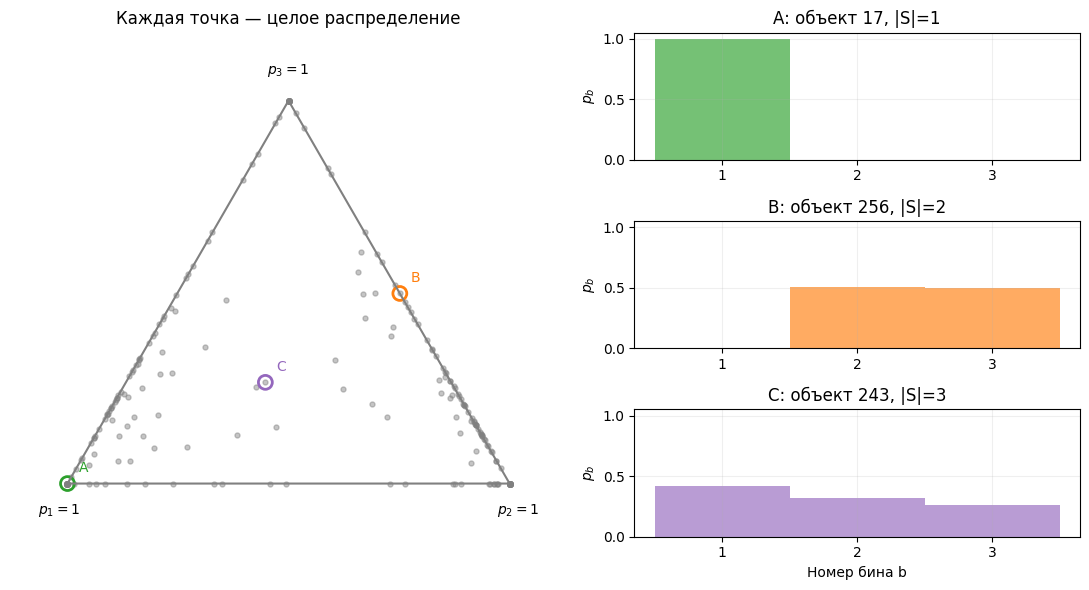

In [ ]:
def validate_histograms(P):
    P = np.asarray(P, dtype=float)
    if P.ndim != 2 or P.shape[1] < 2 or not np.isfinite(P).all():
        raise ValueError('Нужен конечный массив формы (N,B), B >= 2.')
    if np.any(P < 0) or not np.allclose(P.sum(1), 1., atol=1e-10, rtol=1e-10):
        raise ValueError('Вероятности неотрицательны и суммируются в единицу.')
    return P

def active_data(P):
    P = validate_histograms(P)
    mask = P > 0
    logp = np.zeros_like(P)
    np.log(P, out=logp, where=mask)
    return mask.astype(float), logp

def sample_face_component(rho, alpha, n, rng):
    P = np.zeros((n, len(rho)))
    for i in range(n):
        active = rng.random(len(rho)) < rho
        while not active.any():
            active = rng.random(len(rho)) < rho
        g = rng.gamma(alpha[active])
        P[i, active] = g/g.sum()
    return P

def sample_face_mixture(model, n, rng):
    labels = rng.choice(len(model['weights']), size=n, p=model['weights'])
    P = np.zeros((n, model['rho'].shape[1]))
    for k in range(len(model['weights'])):
        members = np.flatnonzero(labels == k)
        P[members] = sample_face_component(model['rho'][k], model['alpha'][k], len(members), rng)
    return P, labels

# Два семейства распределений по трём бинам.
toy_face_rng = np.random.default_rng(19)
toy_face_parameters = dict(weights=np.array([.5, .5]),
    rho=np.array([[.8, .35, .6], [.35, .8, .6]]),
    alpha=np.array([[6., 1., 2.], [1., 6., 2.]]))
toy_P, _ = sample_face_mixture(toy_face_parameters, 260, toy_face_rng)
validate_histograms(toy_P)

# Одна гистограмма на вершине, одна на ребре и одна внутри треугольника.
example_masks = np.array([[1, 0, 0], [0, 1, 1], [1, 1, 1]], dtype=bool)
example_ids = []
for mask in example_masks:
    candidates = np.flatnonzero(np.all((toy_P > 0) == mask, axis=1))
    # Выбираем пример с хорошо видимыми положительными массами.
    example_ids.append(candidates[np.argmax(toy_P[candidates][:, mask].min(axis=1))])
triangle = np.array([[0., 0.], [1., 0.], [.5, np.sqrt(3)/2]])
xy = toy_P@triangle

fig = plt.figure(figsize=(11, 6))
grid = fig.add_gridspec(3, 2, width_ratios=[1.25, 1.])
ax = fig.add_subplot(grid[:, 0])
ax.plot(*triangle[[0, 1, 2, 0]].T, color='grey')
ax.scatter(*xy.T, s=13, alpha=.45, color='grey')
ax.text(-.02, -.07, '$p_1=1$', ha='center')
ax.text(1.02, -.07, '$p_2=1$', ha='center')
ax.text(.5, np.sqrt(3)/2+.06, '$p_3=1$', ha='center')
ax.set(aspect='equal', xlim=(-.13, 1.13), ylim=(-.12, 1.02),
       title='Каждая точка — целое распределение')
ax.axis('off')
for row, (letter, i, color) in enumerate(zip('ABC', example_ids,
                                            ['tab:green', 'tab:orange', 'tab:purple'])):
    ax.scatter(*xy[i], s=100, facecolors='none', edgecolors=color, linewidths=2)
    ax.annotate(letter, xy[i], xytext=(8, 8), textcoords='offset points', color=color)
    hist_ax = fig.add_subplot(grid[row, 1])
    hist_ax.bar([1, 2, 3], toy_P[i], width=1., color=color, alpha=.65)
    hist_ax.set(xticks=[1, 2, 3], ylim=(0, 1.05), ylabel='$p_b$',
                title=f'{letter}: объект {i}, |S|={(toy_P[i]>0).sum()}')
    if row == 2:
        hist_ax.set_xlabel('Номер бина b')
plt.tight_layout(); plt.show()


### Вероятность носителя и плотность на его грани

Вероятность принять пробную маску в компоненте $k$ равна
$$Z_k=1-\prod_{b=1}^B(1-\rho_{kb}).$$
Поэтому вероятность наблюдаемой непустой маски $m_i$ есть
$$q_k(m_i)=\Pr(m_i\mid c_i=k)
=\frac{\prod_{b=1}^B\rho_{kb}^{m_{ib}}(1-\rho_{kb})^{1-m_{ib}}}{Z_k}.$$
Условие непустоты объясняет нормировочный множитель $Z_k$.
Параметр $\rho_{kb}$ относится к пробной маске;
в принятой маске $\Pr(m_{ib}=1\mid c_i=k)=\rho_{kb}/Z_k$.

При фиксированном $S_i$ вектор $p_i$ лежит во внутренности грани симплекса:
его координаты положительны на $S_i$, равны нулю вне $S_i$ и суммируются в единицу.
Размерность такой грани равна $|S_i|-1$. Введём
$$A_{ik}=\sum_{b\in S_i}\alpha_{kb}.$$
Условная плотность положительных координат равна
$$d_{k,S_i}(p_{i,S_i})=
\frac{\Gamma(A_{ik})}{\prod_{b\in S_i}\Gamma(\alpha_{kb})}
\prod_{b\in S_i}p_{ib}^{\alpha_{kb}-1}.$$
Здесь $\Gamma(a)=\int_0^\infty u^{a-1}e^{-u}\,du$ — гамма-функция.
Параметры $\alpha_{kb}/A_{ik}$ задают условные средние активных вероятностей;
увеличение всех $\alpha_{kb}$ на одном носителе в одинаковое число раз
уменьшает разброс вокруг этих средних. На вершине ($|S_i|=1$)
условный закон детерминирован и $d_{k,S_i}=1$.

На каждой грани плотность $d_{k,S_i}$ задана в $|S_i|-1$ свободных
координатах: последняя активная координата определяется нормировкой.
Для вершин используем точечные массы. Сумма этих мер по всем непустым
носителям задаёт одну фиксированную меру для всей смеси.
Плотность компоненты относительно неё равна
$$f_k(p_i)=q_k(m_i)\,d_{k,S_i}(p_{i,S_i}).$$
Первый множитель — вероятность выбрать именно этот носитель,
второй — условная плотность на выбранной грани. Все непустые носители,
включая вершины, имеют положительную вероятность.

При целых $\alpha_{kb}\geq1$ плотность на активной грани — нормированный
многочлен по положительным координатам; при всех $\alpha_{kb}=1$
она равномерна на этой грани. В обучении допускаются любые положительные $\alpha$.


### E-шаг и функции для реализации

Вектор $p_i$ и его маска $m_i$ наблюдаются; скрыт только кластер $c_i$.
Обозначим все параметры смеси через $\theta=(\pi,\rho,\alpha)$.
Наблюдаемая плотность и логарифм правдоподобия равны
$$f_\theta(p_i)=\sum_{k=1}^K\pi_k f_k(p_i),\qquad
\ell(\theta;P)=\sum_{i=1}^N\log f_\theta(p_i).$$
На E-шаге вычисляем ответственности — условные вероятности кластеров:
$$r_{ik}=\Pr(c_i=k\mid p_i,\theta)
=\frac{\pi_k f_k(p_i)}{\sum_{l=1}^K\pi_l f_l(p_i)}.$$
Для устойчивого вычисления введём
$$a_{ik}=\log\pi_k+\log q_k(m_i)+\log d_{k,S_i}(p_{i,S_i}),$$
$$s_i=\operatorname{logsumexp}_{k=1}^K a_{ik}
=\log\sum_{k=1}^K e^{a_{ik}},\qquad
r_{ik}=e^{a_{ik}-s_i},\qquad \ell=\sum_{i=1}^N s_i.$$
В частности,
$$\log d_{k,S_i}
=\log\Gamma(A_{ik})-\sum_{b\in S_i}\log\Gamma(\alpha_{kb})
+\sum_{b\in S_i}(\alpha_{kb}-1)\log p_{ib}.$$
Все суммы с $\log p_{ib}$ идут только по активным координатам.

Реализуйте три функции:

1. `support_logpmf(M, rho)` возвращает матрицу $\log q_k(m_i)$ формы $(N,K)$.
   Здесь `M` — бинарная матрица масок $(N,B)$, `rho` — массив $(K,B)$.
   Вычислите `log_empty` $=\sum_b\log(1-\rho_{kb})$, а затем
   $\log Z_k$ через `log(-expm1(log_empty))`.
2. `face_dirichlet_logpdf(P, alpha)` возвращает матрицу
   $\log d_{k,S_i}(p_{i,S_i})$ формы $(N,K)$.
   Массивы `P` и `alpha` имеют формы $(N,B)$ и $(K,B)$.
   Используйте `gammaln` для $\log\Gamma$.
3. `face_e_step(P, weights, rho, alpha)` возвращает матрицу
   $R=(r_{ik})$ формы $(N,K)$ и скаляр $\ell$.
   Вектор `weights` формы $(K,)$ хранит $\pi$.

Готовая функция `active_data` возвращает маски `M` и массив `L` формы $(N,B)$:
$L_{ib}=\log p_{ib}$ при $b\in S_i$ и $L_{ib}=0$ вне носителя.
Нули в `L` служат только для суммирования по активным координатам;
функция не вычисляет $\log0$. Исходные нулевые вероятности не меняются.


In [ ]:
def support_logpmf(M, rho):
    """Nonempty masks M (N,B), probabilities rho (K,B) -> log pmf (N,K)."""
    raise NotImplementedError

def face_dirichlet_logpdf(P, alpha):
    """P (N,B), alpha (K,B)>0 -> log density on each observed face (N,K)."""
    raise NotImplementedError

def face_e_step(P, weights, rho, alpha):
    """Return responsibilities (N,K) and observed log likelihood (scalar)."""
    raise NotImplementedError


In [ ]:
def test_face_likelihood():
    from itertools import product
    from scipy.integrate import quad
    for B in [2, 3, 6]:
        masks = np.array([m for m in product([0., 1.], repeat=B) if sum(m)>0])
        rho = np.linspace(.2, .8, B)[None, :]
        np.testing.assert_allclose(np.exp(support_logpmf(masks, rho)).sum(), 1., atol=1e-12)
    vertices = np.eye(3)
    np.testing.assert_allclose(face_dirichlet_logpdf(vertices, np.array([[2., 3., 4.]])), 0., atol=1e-12)
    rho = np.array([[.5, .5, .5]])
    np.testing.assert_allclose(support_logpmf(vertices, rho), np.log(1/7))
    integral = quad(lambda t: np.exp(face_dirichlet_logpdf(
        np.array([[t, 1-t]]), np.array([[2., 3.]]))[0, 0]), 0., 1.)[0]
    np.testing.assert_allclose(integral, 1., atol=1e-10)
    R, ll = face_e_step(np.array([[1., 0], [.5, .5]]), np.array([.5, .5]),
        np.array([[.8, .2], [.2, .8]]), np.ones((2, 2)))
    np.testing.assert_allclose(R[0], [16/17, 1/17])
    np.testing.assert_allclose(R[1], [.5, .5])
    np.testing.assert_allclose(R.sum(1), 1.)
    assert np.isfinite(ll)

check('Likelihood на симплексе', test_face_likelihood)


### Численный M-шаг: generalized EM

При фиксированных ответственностях $r_{ik}$ максимизируем
$$Q(\theta)=\sum_{i=1}^N\sum_{k=1}^K r_{ik}
\left[\log\pi_k+\log q_k(m_i)+\log d_{k,S_i}(p_{i,S_i})\right].$$
Пусть $N_k=\sum_i r_{ik}$ — суммарный вес объектов в компоненте $k$.
Тогда $\pi_k^{\rm new}=N_k/N$. Оставшаяся задача распадается на отдельную
оптимизацию $\sum_i r_{ik}\log q_k(m_i)$ по $\rho_k$ и
$\sum_i r_{ik}\log d_{k,S_i}(p_{i,S_i})$ по $\alpha_k$ для каждой компоненты.

Ниже дан численный оптимизатор с аналитическими градиентами.
Внутри компоненты он использует нормированные веса $w_i=r_{ik}/N_k$,
взвешенную частоту активности `freq` $=\sum_i w_i m_i$ и
`mean_logp` $=\sum_i w_i L_i$. Деление цели на $N_k$ не меняет её максимума.
В переменных оптимизатора `eta` $=\log(\rho_k/(1-\rho_k))$,
так что $\rho_k=\operatorname{sigmoid}(\mathrm{eta})$;
`log_alpha` — покоординатный логарифм $\alpha_k$.

Ограничим логиты $\rho$ интервалом $[-8,8]$, а $\alpha$ — интервалом
$[0.05,500]$. Это фиксированное семейство параметров. После каждого численного
обновления проверяем, что соответствующая часть $Q$ не уменьшилась; иначе
сохраняем старое значение. Увеличения $Q$ достаточно для подъёма likelihood
(generalized EM, GEM), даже если оптимизатор не нашёл точный максимум.
Вывод градиентов приведён в конспекте преподавателя.

Вопрос: почему частота активности не всегда равна $\rho_{kb}$?
Почему вершины дают информацию о масках, но не о параметрах Дирихле
на этой вершине?


In [ ]:
def numerical_face_m_step(P, R, rho, alpha, learn_shapes=True):
    M, L = active_data(P)
    B = P.shape[1]
    nk = R.sum(0)
    if np.any(nk < 1e-10):
        raise FloatingPointError('Пустая компонента: нужен другой старт.')
    new_rho, new_alpha = rho.copy(), alpha.copy()
    for k in range(R.shape[1]):
        w = R[:, k]/nk[k]
        freq, mean_logp = w@M, w@L
        def mask_objective(eta):
            r = expit(eta)
            log_empty = -np.logaddexp(0., eta).sum()
            nonempty = -np.expm1(log_empty)
            value = freq@eta-np.logaddexp(0., eta).sum()-np.log(nonempty)
            gradient = freq-r/nonempty
            return -value, -gradient
        eta0 = np.log(rho[k])-np.log1p(-rho[k])
        result = minimize(mask_objective, eta0, jac=True, method='L-BFGS-B',
                          bounds=[(-8., 8.)]*B, options={'maxiter':80, 'ftol':1e-11})
        if np.isfinite(result.fun) and result.fun <= mask_objective(eta0)[0]:
            new_rho[k] = expit(result.x)
        if learn_shapes:
            def shape_objective(log_alpha):
                a = np.exp(log_alpha)
                totals = M@a
                value = w@gammaln(totals)-freq@gammaln(a)+mean_logp@(a-1)
                gradient = M.T@(w*digamma(totals))-freq*digamma(a)+mean_logp
                return -value, -gradient*a
            old = np.log(alpha[k])
            result = minimize(shape_objective, old, jac=True, method='L-BFGS-B',
                bounds=[(np.log(.05), np.log(500.))]*B,
                options={'maxiter':100, 'ftol':1e-10, 'gtol':1e-5})
            if np.isfinite(result.fun) and result.fun <= shape_objective(old)[0]:
                new_alpha[k] = np.exp(result.x)
    return nk/len(P), new_rho, new_alpha

def fit_face_mixture(P, K, seed=0, n_init=3, max_iter=80, tol=1e-6, learn_shapes=True):
    P = validate_histograms(P)
    M, _ = active_data(P)
    rng = np.random.default_rng(seed)
    best = None
    for restart in range(n_init):
        labels = KMeans(K, n_init=1, random_state=int(rng.integers(2**30))).fit_predict(np.sqrt(P))
        R = .98*np.eye(K)[labels]+.02/K
        weights = R.mean(0)
        rho = np.clip(R.T@M/R.sum(0)[:, None], .05, .95)
        alpha = np.ones((K, P.shape[1]))
        try:
            weights, rho, alpha = numerical_face_m_step(P, R, rho, alpha, learn_shapes)
            R, ll = face_e_step(P, weights, rho, alpha)
            history, converged = [ll], False
            for iteration in range(max_iter):
                weights, rho, alpha = numerical_face_m_step(P, R, rho, alpha, learn_shapes)
                R, ll = face_e_step(P, weights, rho, alpha)
                gain = ll-history[-1]
                if gain < -1e-8*(1+abs(history[-1])):
                    raise RuntimeError('Likelihood уменьшился: проверьте численный M-шаг.')
                history.append(ll)
                if gain <= tol*(1+abs(history[-2])):
                    converged = True
                    break
            model = dict(weights=weights, rho=rho, alpha=alpha,
                         history=np.array(history), converged=converged)
            if best is None or ll > best['history'][-1]:
                best = model
        except FloatingPointError:
            continue
    if best is None:
        raise RuntimeError('Все старты потеряли компоненту.')
    return best

def predict_face(model, P):
    return face_e_step(P, model['weights'], model['rho'], model['alpha'])[0]


In [ ]:
def test_face_em():
    fitted = fit_face_mixture(toy_P, 2, seed=21, n_init=2)
    assert np.all(np.diff(fitted['history']) >= -1e-6)
    R = predict_face(fitted, toy_P)
    np.testing.assert_allclose(R.sum(1), 1.)
    assert np.isfinite(predict_face(fitted, np.eye(3))).all()
    final = face_e_step(toy_P, fitted['weights'], fitted['rho'], fitted['alpha'])[1]
    np.testing.assert_allclose(final, fitted['history'][-1])

if ready('Likelihood на симплексе'):
    check('EM на симплексе', test_face_em)


### Кластеризация точек на симплексе

Обучите смесь на `toy_P` и раскрасьте точки по наиболее вероятной компоненте.
Сравните объекты на рёбрах и во внутренности треугольника.

Вопрос: почему точка на вершине может иметь неопределённую принадлежность
к кластеру? Какие сведения о компоненте несёт её носитель?


In [ ]:
if ready('EM на симплексе'):
    toy_face_model = fit_face_mixture(toy_P, 2, seed=21, n_init=3)
    toy_face_R = predict_face(toy_face_model, toy_P)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].plot(*triangle[[0, 1, 2, 0]].T, color='grey')
    axes[0].scatter(*xy.T, c=toy_face_R.argmax(1), s=12, cmap='tab10', alpha=.7)
    axes[0].text(-.02, -.07, '$p_1=1$', ha='center')
    axes[0].text(1.02, -.07, '$p_2=1$', ha='center')
    axes[0].text(.5, np.sqrt(3)/2+.06, '$p_3=1$', ha='center')
    axes[0].set(aspect='equal', xlim=(-.13, 1.13), ylim=(-.12, 1.02),
                title='EM: кластеры на симплексе')
    axes[0].axis('off')
    axes[1].plot(toy_face_model['history'], marker='.')
    axes[1].set(xlabel='M-шаг', ylabel='log likelihood', title='Подъём GEM')
    plt.tight_layout(); plt.show()


## Задание 4. Кластеризация распределений: эвристики и генеративные модели

Даны $N$ нормированных гистограмм $p_i\in\Delta^{B-1}$. Координата $p_{ib}$
— вероятность бина или категории $b$ у распределения $i$. Допускаются точные
нули, нерегулярные и многомодальные формы. Требуется сгруппировать целые
распределения и назначать кластер новому объекту. Метка $c_i$ относится ко всей
строке $p_i$ матрицы $P$; число мод одной гистограммы не определяет число кластеров.

Если заданы высоты плотности $h_b$ на интервалах ширины $\Delta_b$,
вероятности равны $p_b=h_b\Delta_b$. Для дискретных категорий вход уже имеет
вид масс. Числовую опору можно использовать, когда она известна из условия.

Сначала предложите план сравнения. Какие свойства должна сохранять
кластеризация? Что предполагает генеративная модель о носителе и положительных
вероятностях? Когда эти предположения могут оказаться неверными?

1. Постройте эвристический подход: признаки → PCA → GMM из заданий 1–2.
2. Обучите смесь DCD из задания 3 и объясните смысл её параметров.
   Постройте график обучающего log likelihood по M-шагам и проверьте его рост.
3. Сравните представителей, устойчивость и отложенные разбиения после
   фиксации параметров. По изображениям проверьте, что модель умеет генерировать
   разумные гистограммы с нулями.
4. Выполните абляцию «только носитель» и контроль нарушения модельных предположений.

Ни один метод не обязан выигрывать на всех возможных распределениях.


### Базовые представления

Для вероятностей геометрия Хеллингера задаётся
$$H^2(p,q)=\tfrac12\sum_b(\sqrt{p_b}-\sqrt{q_b})^2.$$
Поэтому $\sqrt p$ — удобные признаки, сохраняющие нули. После усечения PCA
часть информации теряется. Прямые вероятности имеют вырожденную полную
ковариацию в $\mathbb R^B$ из-за $\sum_b p_b=1$; можно работать в проекции.
Для числовых бинов полезно сравнить также моменты.

Такие конвейеры могут хорошо кластеризовать, но выбранная GMM задаёт
плотность в пространстве признаков. Модель DCD задаёт распределение
непосредственно на наблюдаемых объектах и их носителях. Её предположения
явны и проверяемы через генерацию и отложенное likelihood в одной модели.


Распределений: 720 | бинов: 64 | доля точных нулей: 0.30082465277777776


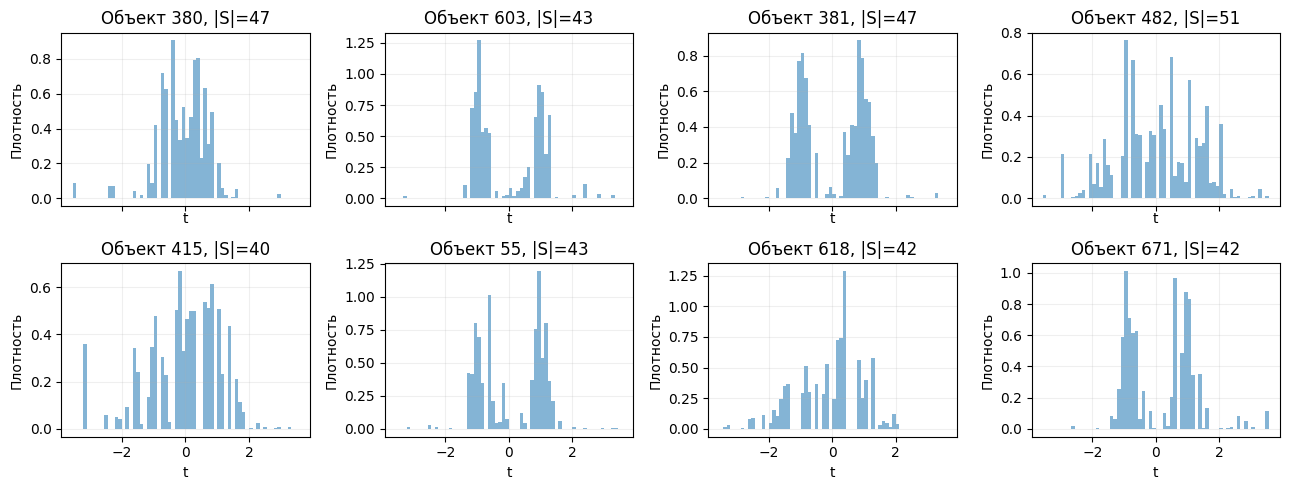

In [ ]:
def generate_histograms(seed=SEED, n_objects=720, B=64):
    rng = np.random.default_rng(seed)
    centers = np.linspace(-3.5, 3.5, B)
    step = centers[1]-centers[0]
    edges = np.r_[centers-step/2, centers[-1]+step/2]
    t = centers
    templates = np.array([
        np.exp(-.5*(t/.9)**4), np.exp(-((t*t-1)/.65)**2),
        np.exp(-.5*((t+.4)/.85)**2)+.4*np.exp(-.5*((t-1.5)/.6)**2),
        np.exp(-.5*((t-.4)/.85)**2)+.4*np.exp(-.5*((t+1.5)/.6)**2)])
    templates /= templates.sum(1, keepdims=True)
    alpha = .12+100*templates
    rho = .62+.25*templates/templates.max(1, keepdims=True)
    labels = np.arange(n_objects)%4
    rng.shuffle(labels)
    P = np.zeros((n_objects, B))
    for i, k in enumerate(labels):
        P[i] = sample_face_component(rho[k], alpha[k], 1, rng)[0]
    return P, edges, labels

def make_seminar_data():
    P, edges, hidden_y = generate_histograms()
    def simulation_audit():
        return hidden_y.copy()
    return P, edges, simulation_audit

P, edges, simulation_audit = make_seminar_data()
validate_histograms(P)
widths = np.diff(edges)
centers = (edges[:-1]+edges[1:])/2
K = 4  # Задано учебным условием до открытия меток.
ids = np.random.default_rng(42).permutation(len(P))
train_ids, test_ids = ids[:480], ids[480:]
P_train, P_test = P[train_ids], P[test_ids]
print('Распределений:', len(P), '| бинов:', P.shape[1],
      '| доля точных нулей:', np.mean(P == 0))
fig, axes = plt.subplots(2, 4, figsize=(13, 5), sharex=True)
for ax, i in zip(axes.flat, train_ids[:8]):
    plot_histogram(ax, P[i]/widths, edges, fill=True, alpha=.55)
    ax.set_title(f'Объект {i}, |S|={(P[i]>0).sum()}')
    ax.set(xlabel='t', ylabel='Плотность')
plt.tight_layout(); plt.show()


### Реализуйте эвристический baseline и сравните с EM

Используйте набор из 720 распределений по $B=64$ бинам, показанный выше.
Разделение — 480 обучающих и 240 отложенных объектов. Все преобразования,
параметры и инициализации оцениваются только на обучении. Истинные метки
будут открыты в `simulation_audit` после фиксации методов.

Реализуйте `fit_distribution_clustering`. Возвращайте `train_labels`,
`test_labels` и описание `description`. Используйте собственный Gaussian EM
по выбранным признакам. Затем добавьте генеративную смесь DCD через
`fit_face_mixture`. Данные сохраняются с исходными нулями во всех методах.


In [ ]:
def fit_distribution_clustering(P_fit, P_new, K, seed):
    # TODO: выберите признаки, обучите преобразование только на P_fit,
    # примените свой fit_diag_gmm и назначьте метки P_new.
    # Верните train_labels, test_labels, description.
    raise NotImplementedError


In [ ]:
def test_distribution_method():
    result = fit_distribution_clustering(P_train[:100], P_test[:11], K, 51)
    for key, n in [('train_labels', 100), ('test_labels', 11)]:
        labels = np.asarray(result[key])
        assert labels.shape == (n,) and np.issubdtype(labels.dtype, np.integer)
        assert np.all((0 <= labels) & (labels < K))
    assert isinstance(result['description'], str)
    one = fit_distribution_clustering(P_train[:100], P_test[3:4], K, 51)
    assert one['test_labels'][0] == result['test_labels'][3]
    boundary = fit_distribution_clustering(np.eye(4), np.eye(4)[:2], 2, 51)
    assert boundary['test_labels'].shape == (2,)

if ready('E-шаг', 'EM'):
    check('Эвристический метод', test_distribution_method)


In [ ]:
def fit_raw_baseline(P_fit, P_new, seed=12):
    pca = PCA(min(8, P_fit.shape[1]-1), svd_solver='full').fit(P_fit)
    A, B = pca.transform(P_fit), pca.transform(P_new)
    model = GaussianMixture(K, covariance_type='full', n_init=12,
                            reg_covar=1e-4, random_state=seed).fit(A)
    return dict(train_labels=model.predict(A), test_labels=model.predict(B))

methods = {'Прямые массы → PCA → GMM': fit_raw_baseline(P_train, P_test)}
if ready('Эвристический метод'):
    methods['Корни масс → PCA → GMM'] = fit_distribution_clustering(P_train, P_test, K, 12)
if ready('EM на симплексе'):
    face_model = fit_face_mixture(P_train, K, seed=8, n_init=3)
    methods['Генеративная смесь DCD'] = dict(
        train_labels=predict_face(face_model, P_train).argmax(1),
        test_labels=predict_face(face_model, P_test).argmax(1))
    support_model = fit_face_mixture(P_train, K, seed=8, n_init=3, learn_shapes=False)
    methods['DCD: только носитель'] = dict(
        train_labels=predict_face(support_model, P_train).argmax(1),
        test_labels=predict_face(support_model, P_test).argmax(1))
    print('DCD: сходимость', face_model['converged'],
          '| шагов', len(face_model['history'])-1,
          '| средний test log likelihood', face_e_step(P_test, face_model['weights'],
              face_model['rho'], face_model['alpha'])[1]/len(P_test))


### Логарифм правдоподобия по M-шагам

Массив `face_model['history']` хранит обучающий логарифм правдоподобия
$\ell(\theta^{(t)};P_{\rm train})$. Элемент с индексом $t=0$ соответствует
параметрам после инициализации; элемент $t\geq1$ — параметрам после $t$
M-шагов цикла. Последующий E-шаг вычисляет ответственности для этих параметров.

Вопрос: согласуется ли график с условием принятия численного M-шага?
Можно ли по выходу на плато сделать вывод о глобальном максимуме?


In [ ]:
if ready('EM на симплексе'):
    history = face_model['history']
    m_steps = np.arange(len(history))
    plt.figure(figsize=(8, 3.6))
    plt.plot(m_steps, history, marker='o')
    plt.xlabel('M-шаг')
    plt.ylabel('log likelihood на обучении')
    plt.title('EM для смеси DCD: обучение на гистограммах')
    plt.tight_layout(); plt.show()


### Проверка генеративного смысла

Сравните отдельные объекты со сгенерированными из обученной модели.
Выбранная маска отвечает за расположение точных нулей, параметры Дирихле —
за соотношение положительных вероятностей. Условное среднее при фиксированной
маске $S$ равно $\alpha_{kb}/\sum_{j\in S}\alpha_{kj}$ на $b\in S$;
безусловное среднее дополнительно усредняет по маскам.

Покажите по несколько представителей каждого кластера. Затем сравните
разбиения от трёх инициализаций: ARI между двумя предсказанными разбиениями
не требует истинных меток. Устойчивость всё ещё не гарантирует полезности групп.


In [ ]:
def plot_clusters(P_fit, labels, title):
    fig, axes = plt.subplots(1, K, figsize=(13, 2.8), sharey=True)
    for k, ax in enumerate(axes):
        members = np.flatnonzero(labels == k)
        for j in members[:4]:
            plot_histogram(ax, P_fit[j]/widths, edges, color='grey', alpha=.25)
        if len(members):
            plot_histogram(ax, P_fit[members].mean(0)/widths, edges, color='navy', linewidth=2)
        ax.set_title(f'Кластер {k}, N={len(members)}'); ax.set_xlabel('t')
    axes[0].set_ylabel('Плотность')
    fig.suptitle(title); plt.tight_layout(); plt.show()

for name, result in methods.items():
    plot_clusters(P_train, result['train_labels'], name)
if ready('EM на симплексе'):
    generated, _ = sample_face_mixture(face_model, 4, np.random.default_rng(71))
    validate_histograms(generated)
    fig, axes = plt.subplots(1, 4, figsize=(13, 2.7), sharey=True)
    for ax, p in zip(axes, generated):
        plot_histogram(ax, p/widths, edges, fill=True, alpha=.6)
        ax.set_title(f'Сгенерировано, |S|={(p>0).sum()}')
    plt.tight_layout(); plt.show()
    labels_by_seed = [predict_face(fit_face_mixture(P_train, K, seed=s, n_init=3), P_test).argmax(1)
                      for s in [11, 22, 33]]
    table(['Seed A', 'Seed B', 'ARI между разбиениями'], [
        [a, b, adjusted_rand_score(labels_by_seed[i], labels_by_seed[j])]
        for i, a in enumerate([11, 22, 33]) for j, b in enumerate([11, 22, 33]) if i<j])


### План и интерпретация

До открытия меток запишите: какие ограничения вводит каждый метод; что
определяет сходство; какова роль носителя; что теряет PCA; как проверялось
обучение и что показали сгенерированные объекты. Для абляции «только носитель»
параметры активных распределений фиксируются равными единице: это равномерные
плотности на гранях. Что эта модель сможет и не сможет различать?


## 5. Итоговый аудит и контроль модели

После фиксации методов откройте метки и оцените отложенные объекты.
Данные сгенерированы из описанной модели с четырьмя профилями параметров;
метки при обучении не используются. ARI инвариантен к нумерации кластеров,
NMI — нормированная взаимная информация. Не настраивайте параметры по этим ответам.

Не сравнивайте напрямую log likelihood PCA-GMM и DCD: плотности определены
на разных пространствах и относительно разных мер. Для сравнения кластеризации
используем общие метрики разбиения, устойчивость и интерпретацию.


In [ ]:
audit_truth = simulation_audit()
table(['Метод', 'Test ARI', 'Test NMI'], [
    [name, adjusted_rand_score(audit_truth[test_ids], result['test_labels']),
     normalized_mutual_info_score(audit_truth[test_ids], result['test_labels'])]
    for name, result in methods.items()])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for k in range(K):
    members = audit_truth == k
    plot_histogram(axes[0], P[members].mean(0)/widths, edges, label=f'Семейство {k}')
    axes[1].plot(centers, (P[members]>0).mean(0), label=f'Семейство {k}')
axes[0].set(xlabel='t', ylabel='Плотность', title='Средние распределения')
axes[1].set(xlabel='t', ylabel='Доля активных объектов', title='Активность координат')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()


### Контроль нарушения предположений

Применим ко всем объектам $p'_b=p_b^2/\sum_jp_j^2$. Преобразование сохраняет
точные нули и усиливает различия положительных масс. На каждой грани оно
обратимо, но семейство Дирихле не замкнуто относительно такого преобразования.
Повторно обучите модели на преобразованных обучающих объектах и назначьте
кластеры преобразованным тестовым. Размеры разбиений и параметры фиксированы.
Такой контроль отделяет успешное восстановление собственной модели
от поведения при изменении закона данных.


In [ ]:
P_power = P**2
P_power /= P_power.sum(1, keepdims=True)
assert np.array_equal(P_power == 0, P == 0)
control = {'Прямые массы → PCA → GMM': fit_raw_baseline(P_power[train_ids], P_power[test_ids])}
if ready('Эвристический метод'):
    control['Корни масс → PCA → GMM'] = fit_distribution_clustering(
        P_power[train_ids], P_power[test_ids], K, 12)
if ready('EM на симплексе'):
    power_model = fit_face_mixture(P_power[train_ids], K, seed=8, n_init=3)
    control['Генеративная смесь DCD'] = dict(
        test_labels=predict_face(power_model, P_power[test_ids]).argmax(1))
table(['Метод', 'Test ARI после преобразования', 'Test NMI'], [
    [name, adjusted_rand_score(audit_truth[test_ids], result['test_labels']),
     normalized_mutual_info_score(audit_truth[test_ids], result['test_labels'])]
    for name, result in control.items()])


Вопрос: улучшилось ли качество только из-за согласования генератора
и likelihood? Какие зависимости между нулями модель не описывает?
Когда нужна более гибкая условная модель на гранях? Почему более сложный
генеративный подход не обязан превосходить эвристику в каждом опыте?


## Приложение A. Транспортное расстояние и медоиды

Для дискретных мер на общих упорядоченных центрах $t_1<\cdots<t_B$ точно
$$W_1(p,q)=\sum_{b=1}^{B-1}|F_p(t_b)-F_q(t_b)|(t_{b+1}-t_b),
\qquad F_p(t_b)=\sum_{j\leq b}p_j.$$
Формула относится к массам в центрах бинов. Для непрерывных кусочно
постоянных плотностей интеграл CDF внутри бинов вычисляется иначе.

Здесь сдвинуть массу в соседний бин дешевле, чем перенести её на другой конец
оси. K-means напрямую с произвольным расстоянием не работает: среднее
минимизирует сумму квадратов евклидовых расстояний. Вместо него используем
медоиды — представители выбираются из обучающих объектов, обновление
минимизирует сумму расстояний внутри группы. Это локальная оптимизация.

Самостоятельно: реализуйте `wasserstein_matrix` и `fit_w1_medoids`.
На каждом шаге назначьте ближайший медоид и выберите внутри каждой группы
объект с минимальной суммой расстояний. Сделайте несколько стартов.
Оцените сложность хранения $O(N^2)$ и чувствительность к сдвигу.


In [ ]:
def wasserstein_matrix(P1, P2, centers):
    """Return pairwise W1 distances, shape (len(P1),len(P2))."""
    raise NotImplementedError

def fit_w1_medoids(P_fit, P_new, K, centers, seed=8, n_init=6):
    """Return train_labels, test_labels, medoid_ids, cost."""
    raise NotImplementedError


In [ ]:
def test_transport():
    from scipy.stats import wasserstein_distance
    P0 = np.eye(3)
    grid = np.array([-2., 0., 3.])
    D = wasserstein_matrix(P0, P0, grid)
    np.testing.assert_allclose(D, np.abs(grid[:, None]-grid[None, :]))
    p, q = np.array([.3, .2, .5]), np.array([.1, .7, .2])
    np.testing.assert_allclose(wasserstein_matrix(p[None], q[None], grid)[0, 0],
                               wasserstein_distance(grid, grid, p, q))
    result = fit_w1_medoids(P_train[:80], P_test[:9], K, centers, n_init=2)
    assert result['test_labels'].shape == (9,)
    assert len(np.unique(result['medoid_ids'])) == K

check('Транспорт', test_transport)
if ready('Транспорт'):
    transport = fit_w1_medoids(P_train, P_test, K, centers)
    plot_clusters(P_train, transport['train_labels'], 'W1: медоиды')
    table(['Метод', 'Test ARI', 'Test NMI'], [
        ['W1: медоиды', adjusted_rand_score(audit_truth[test_ids], transport['test_labels']),
         normalized_mutual_info_score(audit_truth[test_ids], transport['test_labels'])]])


## Приложение B. Если число кластеров неизвестно

В основной задаче $K=4$ задано. Для другой задачи можно сравнивать $K$ по
внутренней валидации, BIC, устойчивости и смыслу групп. Пример ниже фиксирует
одно пространство sqrt-масс → PCA(8), обучает его только на training
и сравнивает GMM в нём:
$$\mathrm{BIC}=-2\ell(\widehat\theta)+m\log N,\qquad
m=(K-1)+Kd+K d(d+1)/2$$
для полной ковариации. Меньше — лучше. Обычный вывод BIC опирается на
регулярные асимптотические предположения; смеси имеют особые точки, поэтому
здесь это практический ориентир. Число компонент, лучше описывающее плотность,
может отличаться от числа содержательных семейств. Не выбирайте по тестовому ARI.


In [ ]:
bic_pca = PCA(8, svd_solver='full').fit(np.sqrt(P_train))
Z_bic = bic_pca.transform(np.sqrt(P_train))
bic_values = []
for k in range(1, 8):
    model = GaussianMixture(k, covariance_type='full', reg_covar=1e-4,
                            n_init=4, random_state=71).fit(Z_bic)
    bic_values.append(model.bic(Z_bic))
plt.plot(range(1, 8), bic_values, marker='o')
plt.xlabel('K'); plt.ylabel('BIC'); plt.title('Один фиксированный набор признаков')
plt.show()


## Приложение C. Совместная кластеризация через VAE

Сделаем условное распределение на симплексе более гибким, сохранив механизм
точных нулей. Генеративная модель:
$$c\sim\operatorname{Cat}(\pi),\qquad
z\mid c=k\sim\mathcal N(\mu_k,\operatorname{diag}(v_k)),$$
$$m\mid z\sim\text{непустая Bernoulli-маска с }\rho_\theta(z),\qquad
p_{S(m)}\mid m,z\sim\operatorname{Dirichlet}(\alpha_{\theta,S(m)}(z)).$$
Неактивные координаты равны нулю. Декодер предсказывает параметры
$\rho_\theta(z)$ и $\alpha_\theta(z)$; likelihood использует ту же меру
на гранях, что и EM. Маска $m(p)$ наблюдается: сэмплировать её при
вычислении likelihood или дифференцировать сквозь дискретный сэмпл не требуется.

Энкодер задаёт гауссовское $q_\phi(z\mid p)$ и получает $\sqrt p$ вместе
с маской. Сумма по скрытому кластеру вычисляется точно:
$$p_\psi(z)=\sum_k\pi_k\mathcal N(z;\mu_k,\operatorname{diag}(v_k)).$$
Оптимизируем ELBO
$$\mathcal L(p)=\mathbb E_q[\log f_\theta(p\mid z)+\log p_\psi(z)
-\log q_\phi(z\mid p)].$$
Это соответствует $q(c,z\mid p)=q_\phi(z\mid p)p_\psi(c\mid z)$.
Все параметры энкодера, декодера и смеси в prior обучаются совместно.
Кластерные вероятности оцениваем как
$$\widehat r_k(p)=\frac1S\sum_{s=1}^S p_\psi(c=k\mid z^{(s)}),\qquad
z^{(s)}\sim q_\phi(z\mid p).$$
Это приближение постериора выбранной модели, а не отдельная GMM над готовыми признаками.

Для инициализации сначала обучаем энкодер и декодер 100 эпох с нормальным
prior, затем инициализируем смесь по обучающим латентным средним и проводим
350 эпох совместной оптимизации. Тест не выбирает эпоху или чекпойнт.
Монте-Карло оценка ELBO стохастична и не обязана монотонно расти.


In [ ]:
if RUN_VAE:
    import torch
    from torch import nn
    from torch.nn import functional as F
    torch.manual_seed(42)
    torch.set_num_threads(1)

    class MixtureFaceVAE(nn.Module):
        def __init__(self, B, K=4, latent=4):
            super().__init__()
            self.encoder = nn.Sequential(nn.Linear(2*B, 96), nn.Tanh(),
                                         nn.Linear(96, 64), nn.Tanh())
            self.mu, self.logvar = nn.Linear(64, latent), nn.Linear(64, latent)
            self.decoder = nn.Sequential(nn.Linear(latent, 64), nn.Tanh(),
                                         nn.Linear(64, 96), nn.Tanh())
            self.mask_logits, self.alpha_logits = nn.Linear(96, B), nn.Linear(96, B)
            self.prior_logits = nn.Parameter(torch.zeros(K))
            self.prior_mu = nn.Parameter(torch.zeros(K, latent))
            self.prior_logvar = nn.Parameter(torch.zeros(K, latent))
            self.log2pi = float(np.log(2*np.pi))

        def encode(self, p):
            h = self.encoder(torch.cat((p.sqrt(), (p>0).to(p.dtype)), dim=1))
            return self.mu(h), self.logvar(h).clamp(-10, 6)

        def decode(self, z):
            h = self.decoder(z)
            return self.mask_logits(h).clamp(-8, 8), (F.softplus(self.alpha_logits(h))+.05).clamp(max=500)

        def log_likelihood(self, p, z):
            # p: (N,B), z: (S,N,latent); same mixed face measure as EM.
            logits, alpha = self.decode(z)
            mask = (p>0).to(p.dtype)
            logp = torch.log(torch.where(p>0, p, torch.ones_like(p)))
            log_empty = F.logsigmoid(-logits).sum(-1)
            log_nonempty = torch.log(-torch.expm1(log_empty))
            log_mask = (mask*F.logsigmoid(logits)+(1-mask)*F.logsigmoid(-logits)).sum(-1)-log_nonempty
            totals = (mask*alpha).sum(-1)
            log_face = torch.lgamma(totals)-(mask*torch.lgamma(alpha)).sum(-1)+((alpha-1)*logp).sum(-1)
            return log_mask+log_face

        def component_log_joint(self, z):
            lv = self.prior_logvar.clamp(-8, 6)
            log_normal = -.5*(self.log2pi+lv+
                (z[..., None, :]-self.prior_mu).square()*torch.exp(-lv)).sum(-1)
            return F.log_softmax(self.prior_logits, dim=0)+log_normal

        def elbo(self, p, samples=2, warmup=False):
            mu, lv = self.encode(p)
            noise = torch.randn(samples, *mu.shape, dtype=p.dtype, device=p.device)
            z = mu[None]+noise*torch.exp(.5*lv)[None]
            log_q = -.5*(self.log2pi+lv[None]+
                (z-mu[None]).square()*torch.exp(-lv)[None]).sum(-1)
            log_prior = (-.5*(self.log2pi+z.square()).sum(-1) if warmup
                         else torch.logsumexp(self.component_log_joint(z), dim=-1))
            return (self.log_likelihood(p, z)+log_prior-log_q).mean(0)

        @torch.no_grad()
        def initialize_prior(self, p):
            mu, lv = self.encode(p)
            initial = GaussianMixture(len(self.prior_logits), covariance_type='diag',
                n_init=10, random_state=0).fit(mu.numpy())
            R = initial.predict_proba(mu.numpy())
            qvar = R.T@lv.exp().numpy()/R.sum(0)[:, None]
            self.prior_logits.copy_(torch.as_tensor(np.log(initial.weights_), dtype=p.dtype))
            self.prior_mu.copy_(torch.as_tensor(initial.means_, dtype=p.dtype))
            self.prior_logvar.copy_(torch.as_tensor(np.log(initial.covariances_+qvar), dtype=p.dtype))

        @torch.no_grad()
        def predict_proba(self, p, samples=100, seed=93):
            mu, lv = self.encode(p)
            generator = torch.Generator().manual_seed(seed)
            noise = torch.randn(samples, *mu.shape, dtype=p.dtype, generator=generator)
            z = mu[None]+noise*torch.exp(.5*lv)[None]
            return self.component_log_joint(z).softmax(-1).mean(0).numpy()

        @torch.no_grad()
        def sample_distributions(self, n, seed=94):
            rng = np.random.default_rng(seed)
            weights = self.prior_logits.softmax(0).numpy()
            classes = rng.choice(len(weights), n, p=weights)
            mu = self.prior_mu.numpy()[classes]
            sd = np.exp(.5*self.prior_logvar.clamp(-8, 6).numpy()[classes])
            z = torch.as_tensor(mu+sd*rng.normal(size=mu.shape), dtype=self.prior_mu.dtype)
            logits, alpha = self.decode(z)
            rho = logits.sigmoid().numpy()
            return np.vstack([sample_face_component(r, a, 1, rng)
                              for r, a in zip(rho, alpha.numpy())])

    # Float64 сохраняет различие между точным нулём и очень малой положительной массой.
    vae_train = torch.tensor(P_train, dtype=torch.float64)
    vae_test = torch.tensor(P_test, dtype=torch.float64)
    assert np.array_equal(vae_train.numpy()>0, P_train>0)
    vae = MixtureFaceVAE(P.shape[1], K=K, latent=4).double()
    vae_history = []
    for phase, epochs, lr in [('warmup', 100, .002), ('joint', 350, .001)]:
        if phase == 'joint':
            vae.initialize_prior(vae_train)
        optimizer = torch.optim.Adam(vae.parameters(), lr=lr)
        for epoch in range(epochs):
            total = 0.
            for batch in torch.randperm(len(vae_train)).split(160):
                loss = -vae.elbo(vae_train[batch], samples=2, warmup=phase=='warmup').mean()
                assert torch.isfinite(loss)
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(vae.parameters(), 20.)
                optimizer.step()
                total += len(batch)*loss.item()
            vae_history.append((phase, epoch, total/len(vae_train)))
    vae.eval()
    vae_R = vae.predict_proba(vae_test, samples=100)
    np.testing.assert_allclose(vae_R.sum(1), 1., atol=1e-10)
    vertices = torch.eye(P.shape[1], dtype=torch.float64)
    with torch.no_grad():
        z0 = torch.zeros((1, len(vertices), 4), dtype=torch.float64)
        assert torch.isfinite(vae.log_likelihood(vertices, z0)).all()
        assert torch.isfinite(vae.elbo(vertices, samples=2)).all()
        # Независимая проверка общего likelihood NumPy и PyTorch на гранях.
        example = torch.tensor([[1., 0, 0], [.3, .7, 0], [.2, .3, .5]], dtype=torch.float64)
        tiny = MixtureFaceVAE(3, K=2, latent=4).double()
        z = torch.zeros((1, len(example), 4), dtype=torch.float64)
        logits, alpha = tiny.decode(z)
        reference = support_logpmf((example.numpy()>0).astype(float), logits[0].sigmoid().numpy())
        reference += face_dirichlet_logpdf(example.numpy(), alpha[0].numpy())
        np.testing.assert_allclose(tiny.log_likelihood(example, z)[0].numpy(), np.diag(reference), atol=1e-10)
    generated_vae = vae.sample_distributions(4)
    validate_histograms(generated_vae)
    table(['Метод', 'Test ARI', 'Test NMI'], [[
        'Совместная DCD-VAE', adjusted_rand_score(audit_truth[test_ids], vae_R.argmax(1)),
        normalized_mutual_info_score(audit_truth[test_ids], vae_R.argmax(1))]])
    joint_history = [value for phase, epoch, value in vae_history if phase == 'joint']
    plt.plot(joint_history)
    plt.xlabel('Совместная эпоха'); plt.ylabel('−ELBO на объект')
    plt.title('Все параметры модели оптимизируются совместно'); plt.show()
    fig, axes = plt.subplots(1, 4, figsize=(13, 2.7), sharey=True)
    for ax, p in zip(axes, generated_vae):
        plot_histogram(ax, p/widths, edges, fill=True, alpha=.6)
        ax.set_title(f'Генерация VAE, |S|={(p>0).sum()}')
    plt.tight_layout(); plt.show()
    print('PyTorch', torch.__version__, '| CPU float64 | 100 + 350 эпох | совместная модель')
else:
    print('VAE — необязательное приложение; RUN_VAE = False.')


Вопросы. Где в этой модели возникает метка кластера? Почему на E-шаге
EM и в likelihood VAE не нужно сэмплировать наблюдаемую маску? Какие
ограничения остаются у гауссовского энкодера? Какие выводы можно сделать
из сгенерированных объектов и вероятностей кластеров? Почему более гибкий
декодер может быть сложнее обучить на небольшом наборе данных?

## Что сдать

Реализации Gaussian EM и likelihood смеси на гранях с проверками;
игрушечные опыты; сравнение эвристик и генеративной модели на отложенных
объектах; представителей и сгенерированные распределения; абляцию по
носителю и контроль изменения закона данных; вывод об ограничениях.
VAE — дополнительное задание с совместной кластерной моделью.


## Источники

1. A. P. Dempster, N. M. Laird, D. B. Rubin (1977).
   *Maximum Likelihood from Incomplete Data via the EM Algorithm*.
   [DOI](https://doi.org/10.1111/j.2517-6161.1977.tb01600.x).
2. R. M. Neal, G. E. Hinton (1998). *A View of the EM Algorithm that Justifies
   Incremental, Sparse, and Other Variants*.
   [Авторский PDF](https://www.cs.toronto.edu/~hinton/absps/emk.pdf).
3. M.-L. Tang, Q. Wu, S. Yang, G.-L. Tian (2022). Распределение DCD:
   [полный текст, определения 1–2 и формулы (2)–(4)](https://bura.brunel.ac.uk/bitstream/2438/23914/1/FullText.pdf).
4. scikit-learn. [GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html).
   SciPy. [wasserstein_distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html).
5. D. P. Kingma, M. Welling. *Auto-Encoding Variational Bayes*.
   [arXiv:1312.6114](https://arxiv.org/abs/1312.6114).

Смесь DCD, генератор данных, сравнение методов и декодер совместного VAE —
учебные конструкции на основе указанных идей; они не воспроизводят
численные эксперименты статей.
